# DPSIM Three Machines Infinite Bus Benchmark System - 6 Buses and 3 Generators

SP, DP and EMT Simulation - Unstable

# Run C++ examples

In [1]:
import villas.dataprocessing.readtools as rt
from villas.dataprocessing.timeseries import TimeSeries as ts
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import dpsimpy
from pathlib import Path

# %matplotlib widget

/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:143: SyntaxWarning: invalid escape sequence '\['
  if re.search('\[D\] Stamping .+ into system matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:145: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] System matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:147: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[D\] Stamping .+ into source vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:149: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] Right side vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:151: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] LU decomposition:', log_lines[line_pos]):
/usr/local/lib/python3.13/

# Imports and System Parameters

In [2]:
# ----------- Power System Base (Texas A&M 3MIB Benchmark) -----------

# ======================= CONFIG =======================
USE_FAULT      = True      # False -> no-fault steady-state validation run
USE_GOV        = True      # TurbineGovernorType1 (stabilizes post-fault frequency)
USE_PSS        = True      # PSS1A (damps electromechanical oscillations)
GEN_ORDER      = 5         # 5 -> G1/G2 5th-order (GENSAE), G3 6b-order (GENROE) | 4 -> 4th-order

FINAL_TIME_SP  = 15.0      # Total SP simulation time (s)
FINAL_TIME_DP  = 6.0       # Total DP simulation time (s)
FINAL_TIME_EMT = 6.0       # Total EMT simulation time (s)

T_FAULT_ON     = 1.0       # Three-phase fault inception at Bus 4 (s)
T_FAULT_OFF    = 1.1       # Fault clearing time (100 ms / 6 cycles)

DT_SP          = 1e-3      # SP time step (1 ms)
DT_DP          = 25e-6     # DP time step (25 us)
DT_EMT         = 25e-6     # EMT time step (25 us)
R_PU           = 1e-6      # Minimum series resistance (pu on 100 MVA / 500 kV base)

PSS = dict(Kp=0.0, Kv=0.0, Kw=5.0, T1=0.15, T2=0.03, T3=0.15, T4=0.03, Tw=10.0, Vs_max=0.1, Vs_min=-0.1)
GOV = (0.0, 1.0, 1.0, 0.5, 0.1, 0.05, 0.0, 1.2, 1.0)   # T3, T4, T5, Tc, Ts, R, Tmin, Tmax, OmRef
# ======================================================

F_NOM = 60.0
OMEGA = 2 * np.pi * F_NOM
V_HV = 500e3
V_LV = 18e3
S_BASE = 100e6
Z_BASE = V_HV**2 / S_BASE
TRAFO_RATING = 10_000e6
R_OHM = R_PU * Z_BASE

def xL(x_pu):
    return x_pu * Z_BASE / OMEGA

def vbase(b):
    return V_LV if b < 4 else V_HV

# Generator parameters (.dyr: GENSAE on Buses 1 and 2; GENROE on Bus 3)
GEN = {
    1: dict(name="G1", S=1560e6, P=1404e6, Q=434.409e6, V=1.04, H=4.5, Ld=0.89, Lq=0.66, Ll=0.28,
            Ld_t=0.36, Lq_t=0.66, Td0_t=5.1, Tq0_t=1.0, Ld_s=0.29, Lq_s=0.29, Td0_s=0.06, Tq0_s=0.094, kind="GENSAE", Ka=100.0),
    2: dict(name="G2", S=1560e6, P=1404e6, Q=434.409e6, V=1.04, H=4.5, Ld=0.89, Lq=0.66, Ll=0.28,
            Ld_t=0.36, Lq_t=0.66, Td0_t=5.1, Tq0_t=1.0, Ld_s=0.29, Lq_s=0.29, Td0_s=0.06, Tq0_s=0.094, kind="GENSAE", Ka=100.0),
    3: dict(name="G3", S=890e6,  P=800e6,  Q=466.25e6,  V=1.02, H=3.859, Ld=1.72, Lq=1.679, Ll=0.266,
            Ld_t=0.488, Lq_t=0.8, Td0_t=5.3, Tq0_t=0.625, Ld_s=0.337, Lq_s=0.337, Td0_s=0.048, Tq0_s=0.066, kind="GENROE", Ka=150.0),
}

LOADS   = {4: (1400e6, 100e6), 5: (2000e6, 100e6), 6: (10000e6, 2000e6)}
TRAFOS  = {"T14": (1, 4, 0.00641), "T24": (2, 4, 0.00641), "T35": (3, 5, 0.0112)}
LINES   = {"L45": (4, 5, 0.036), "L56": (5, 6, 0.120)}
V_PF_PU = {4: 1.016913, 5: 0.972777, 6: 1.0}
FAULT_BUS = 4

Path("logs").mkdir(exist_ok=True)

def build_gen(p, domain):
    ns = {"sp": dpsimpy.sp.ph1, "dp": dpsimpy.dp.ph1, "emt": dpsimpy.emt.ph3}[domain]
    if GEN_ORDER == 4:
        g = ns.SynchronGenerator4OrderVBR(p["name"], dpsimpy.LogLevel.off)
        g.set_operational_parameters_per_unit(
            p["S"], V_LV, F_NOM, p["H"], p["Ld"], p["Lq"], p["Ll"],
            p["Ld_t"], p["Lq_t"], p["Td0_t"], p["Tq0_t"]
        )
    else:
        cls = ns.SynchronGenerator5OrderVBR if p["kind"] == "GENSAE" else ns.SynchronGenerator6bOrderVBR
        g = cls(p["name"], dpsimpy.LogLevel.off)
        g.set_operational_parameters_per_unit(
            p["S"], V_LV, F_NOM, p["H"], p["Ld"], p["Lq"], p["Ll"],
            p["Ld_t"], p["Lq_t"], p["Td0_t"], p["Tq0_t"],
            p["Ld_s"], p["Lq_s"], p["Td0_s"], p["Tq0_s"], 0.0
        )

    # Static Exciter (SCRX)
    ep = dpsimpy.signal.ExciterStaticParameters()
    ep.Ta = 1.0; ep.Tb = 1.0; ep.Ka = p["Ka"]; ep.Te = 0.05
    ep.MinEfd = -5.0; ep.MaxEfd = 5.0; ep.Tr = 1e-3; ep.Kbc = 0.0
    e = dpsimpy.signal.ExciterStatic(f"{p['name']}_Exc", dpsimpy.LogLevel.off)
    e.set_parameters(ep)
    g.add_exciter(e)

    # Power System Stabilizer (PSS1A)
    if USE_PSS:
        pp = dpsimpy.signal.PSS1AParameters()
        for k, v in PSS.items():
            setattr(pp, k, v)
        ps = dpsimpy.signal.PSS1A(f"{p['name']}_PSS", dpsimpy.LogLevel.off)
        ps.set_parameters(pp)
        g.add_pss(ps)

    # Turbine Governor Type 1
    if USE_GOV:
        gv = dpsimpy.signal.TurbineGovernorType1(f"{p['name']}_Gov", dpsimpy.LogLevel.off)
        gv.set_parameters(*GOV)
        g.add_governor(gv)

    return g

# Power Flow Initialization
SP + NRP

In [3]:
sim_name_pf = "3MIB_PF"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_pf)

nodes_pf = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_pf, gens_pf = [], {}

for b, p in GEN.items():
    g = dpsimpy.sp.ph1.SynchronGenerator(p["name"], dpsimpy.LogLevel.off)
    g.set_parameters(p["S"], V_LV, p["P"], V_LV * p["V"], dpsimpy.PowerflowBusType.PV, p["Q"], 9.9e9, -9.9e9)
    g.set_base_voltage(V_LV)
    g.connect([nodes_pf[b]])
    comps_pf.append(g)
    gens_pf[b] = g

for b, (P, Q) in LOADS.items():
    l = dpsimpy.sp.ph1.Load(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b))
    l.connect([nodes_pf[b]])
    comps_pf.append(l)

s_pf = dpsimpy.sp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_pf.set_parameters(V_HV)
s_pf.set_base_voltage(V_HV)
s_pf.modify_power_flow_bus_type(dpsimpy.PowerflowBusType.VD)
s_pf.connect([nodes_pf[6]])
comps_pf.append(s_pf)

for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.sp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.set_base_voltage(V_HV)
    t.connect([nodes_pf[a], nodes_pf[b]])
    comps_pf.append(t)

for n, (a, b, x) in LINES.items():
    l = dpsimpy.sp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), 0.0, 0.0)
    l.set_base_voltage(V_HV)
    l.connect([nodes_pf[a], nodes_pf[b]])
    comps_pf.append(l)

sys_pf = dpsimpy.SystemTopology(F_NOM, list(nodes_pf.values()), comps_pf)
lg_pf = dpsimpy.Logger(sim_name_pf)
for b, n in nodes_pf.items():
    lg_pf.log_attribute(f"v_bus{b}", "v", n)

sim_pf = dpsimpy.Simulation(sim_name_pf, dpsimpy.LogLevel.off)
sim_pf.set_system(sys_pf)
sim_pf.set_time_step(1.0)
sim_pf.set_final_time(2.0)
sim_pf.set_domain(dpsimpy.Domain.SP)
sim_pf.set_solver(dpsimpy.Solver.NRP)
sim_pf.set_solver_component_behaviour(dpsimpy.SolverBehaviour.Initialization)
sim_pf.do_init_from_nodes_and_terminals(False)
sim_pf.add_logger(lg_pf)
sim_pf.run()

res_pf = rt.read_timeseries_dpsim(f"logs/{sim_name_pf}/{sim_name_pf}.csv")
ref_pf = {1: (1.04, 50.572), 2: (1.04, 50.572), 3: (1.02, 20.048), 4: (1.016913, 45.691), 5: (0.972777, 14.867), 6: (1.0, 0.0)}
rows = []
for b in range(1, 7):
    v = res_pf[f"v_bus{b}"].values[-1]
    rows.append({
        "Bus": b,
        "V_solved_pu": abs(v) / vbase(b),
        "V_target_pu": ref_pf[b][0],
        "Angle_solved_deg": np.degrees(np.angle(v)),
        "Angle_target_deg": ref_pf[b][1],
    })
display(pd.DataFrame(rows).set_index("Bus"))

column number: 6
results length: 3
real column names: []
complex column names: ['v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']


[10:46:51.298606 L45 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[10:46:51.298639 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[10:46:51.298820 L56 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[10:46:51.298825 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]


,V_solved_pu,V_target_pu,Angle_solved_deg,Angle_target_deg
Bus,,,,
1,1.040000,1.040000,48.049391,50.572
2,1.040000,1.040000,48.049391,50.572
3,1.020000,1.020000,17.818107,20.048
4,1.013882,1.016913,43.164272,45.691
5,0.969466,0.972777,12.638083,14.867
6,1.000000,1.000000,0.000000,0.000


# SP Dynamic Simulation
SynchronGenerator4OrderVBR

In [4]:
sim_name_sp = "3MIB_SP"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_sp)

nodes_sp = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_sp, gs_sp = [], {}

for b, p in GEN.items():
    g = build_gen(p, "sp")
    g.connect([nodes_sp[b]])
    comps_sp.append(g)
    gs_sp[b] = g

for b, (P, Q) in LOADS.items():
    l = dpsimpy.sp.ph1.Load(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0))
    l.connect([nodes_sp[b]])
    comps_sp.append(l)

s_sp = dpsimpy.sp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_sp.set_parameters(complex(V_HV, 0.0))
s_sp.set_base_voltage(V_HV)
s_sp.modify_power_flow_bus_type(dpsimpy.PowerflowBusType.VD)
s_sp.connect([nodes_sp[6]])
comps_sp.append(s_sp)

for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.sp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.set_base_voltage(V_HV)
    t.connect([nodes_sp[a], nodes_sp[b]])
    comps_sp.append(t)

for n, (a, b, x) in LINES.items():
    l = dpsimpy.sp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), 0.0, 0.0)
    l.set_base_voltage(V_HV)
    l.connect([nodes_sp[a], nodes_sp[b]])
    comps_sp.append(l)

f_sp = dpsimpy.sp.ph1.Switch("Br_fault", dpsimpy.LogLevel.off)
f_sp.set_parameters(1e9, 1e-2, False)
f_sp.connect([nodes_sp[FAULT_BUS], dpsimpy.sp.SimNode.gnd])
comps_sp.append(f_sp)

st_sp = dpsimpy.SystemTopology(F_NOM, list(nodes_sp.values()), comps_sp)
st_sp.init_with_powerflow(sys_pf, dpsimpy.Domain.SP)
s_sp.set_parameters(complex(V_HV, 0.0))

for b, g in gs_sp.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_sp[b].initial_single_voltage(),
    )

lg_sp = dpsimpy.Logger(sim_name_sp)
for b, n in nodes_sp.items():
    lg_sp.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_sp.items():
    for k, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm"), ("Ef", "Ef"), ("dl", "delta")):
        lg_sp.log_attribute(f"{k}{b}", a, g)
lg_sp.log_attribute("i_fault", "i_intf", f_sp)

sim_sp = dpsimpy.Simulation(sim_name_sp, dpsimpy.LogLevel.off)
sim_sp.set_system(st_sp)
sim_sp.set_time_step(DT_SP)
sim_sp.set_final_time(FINAL_TIME_SP)
sim_sp.set_domain(dpsimpy.Domain.SP)
sim_sp.add_logger(lg_sp)
sim_sp.do_system_matrix_recomputation(True)
if USE_FAULT:
    sim_sp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_ON, f_sp, True))
    sim_sp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_OFF, f_sp, False))
sim_sp.run()
print("SP simulation finished.")

SP simulation finished.


[10:46:52.503949 L45 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[10:46:52.503997 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[10:46:52.504209 L56 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[10:46:52.504215 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[10:46:52.509560 MnaSolverFactory info] creating KLUAdapter solver implementation


1.000000e+00: Handle event time
1.100000e+00: Handle event time


In [5]:
ts_sp = rt.read_timeseries_dpsim("logs/3MIB_SP/3MIB_SP.csv")
for idx in [0, 500, 1050, 2000]:
    t = ts_sp['v_bus5'].time[idx]
    v5 = abs(ts_sp['v_bus5'].values[idx]) / 1e3
    v6 = abs(ts_sp['v_bus6'].values[idx]) / 1e3
    f1 = np.real(ts_sp['wr1'].values[idx]) * 60
    print(f"t={t:.2f}s | V6(Slack)={v6:.1f} kV | V5={v5:.1f} kV | f1={f1:.2f} Hz")

column number: 22
results length: 15001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_fault', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
t=0.00s | V6(Slack)=500.0 kV | V5=484.7 kV | f1=60.00 Hz
t=0.50s | V6(Slack)=500.0 kV | V5=484.8 kV | f1=60.01 Hz
t=1.05s | V6(Slack)=500.0 kV | V5=244.9 kV | f1=60.30 Hz
t=2.00s | V6(Slack)=500.0 kV | V5=399.1 kV | f1=60.43 Hz


# DP Dynamic Simulation #

In [6]:
sim_name_dp = "3MIB_DP"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_dp)

nodes_dp = {i: dpsimpy.dp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
comps_dp, gs_dp = [], {}

# 1. Synchronous Generators + Controls
for b, p in GEN.items():
    g = build_gen(p, "dp")
    g.connect([nodes_dp[b]])
    comps_dp.append(g)
    gs_dp[b] = g

# 2. Constant-Z Loads scaled to PF voltage
for b, (P, Q) in LOADS.items():
    l = dpsimpy.dp.ph1.RXLoad(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(P, Q, vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0))
    l.connect([nodes_dp[b]])
    comps_dp.append(l)

# 3. Infinite Bus at Bus 6
s_dp = dpsimpy.dp.ph1.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_dp.set_parameters(complex(V_HV, 0.0))
s_dp.connect([nodes_dp[6]])
comps_dp.append(s_dp)

# 4. Step-Up Transformers & Transmission Lines (C = 0.0 matches SP and Texas .RAW)
for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.dp.ph1.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, R_OHM, xL(x))
    t.connect([nodes_dp[a], nodes_dp[b]])
    comps_dp.append(t)

for n, (a, b, x) in LINES.items():
    l = dpsimpy.dp.ph1.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(R_OHM, xL(x), 0.0, 0.0)
    l.connect([nodes_dp[a], nodes_dp[b]])
    comps_dp.append(l)

# 5. Three-Phase Fault Switch at Bus 4
f_dp = dpsimpy.dp.ph1.Switch("Br_fault", dpsimpy.LogLevel.off)
f_dp.set_parameters(1e9, 1e-2, False)
f_dp.connect([nodes_dp[FAULT_BUS], dpsimpy.dp.SimNode.gnd])
comps_dp.append(f_dp)

st_dp = dpsimpy.SystemTopology(F_NOM, list(nodes_dp.values()), comps_dp)
st_dp.init_with_powerflow(sys_pf, dpsimpy.Domain.DP)
s_dp.set_parameters(complex(V_HV, 0.0))

# Initialize generator internal states from converged Power Flow
for b, g in gs_dp.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_dp[b].initial_single_voltage(),
    )

# Logging & Execution
lg_dp = dpsimpy.Logger(sim_name_dp)
for b, n in nodes_dp.items():
    lg_dp.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_dp.items():
    for k, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm"), ("Ef", "Ef"), ("dl", "delta")):
        lg_dp.log_attribute(f"{k}{b}", a, g)
lg_dp.log_attribute("i_fault", "i_intf", f_dp)

sim_dp = dpsimpy.Simulation(sim_name_dp, dpsimpy.LogLevel.off)
sim_dp.set_system(st_dp)
sim_dp.set_time_step(DT_DP)
sim_dp.set_final_time(FINAL_TIME_DP)
sim_dp.set_domain(dpsimpy.Domain.DP)
sim_dp.add_logger(lg_dp)
sim_dp.do_system_matrix_recomputation(True)
if USE_FAULT:
    sim_dp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_ON, f_dp, True))
    sim_dp.add_event(dpsimpy.event.SwitchEvent(T_FAULT_OFF, f_dp, False))
sim_dp.run()
print("DP simulation finished.")

DP simulation finished.1.000000e+00: Handle event time



[10:47:00.978285 MnaSolverFactory info] creating KLUAdapter solver implementation


1.100000e+00: Handle event time


# EMT Three-Phase Dynamic Simulation
SynchronGenerator4OrderVBR

In [7]:
sim_name_emt = "3MIB_EMT"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_emt)
to3 = lambda v: dpsimpy.Math.single_phase_parameter_to_three_phase(float(v))

nodes_emt = {i: dpsimpy.emt.SimNode(f"n{i}", dpsimpy.PhaseType.ABC) for i in range(1, 7)}
comps_emt, gs_emt = [], {}

for b, p in GEN.items():
    g = build_gen(p, "emt")
    g.connect([nodes_emt[b]])
    comps_emt.append(g)
    gs_emt[b] = g

for b, (P, Q) in LOADS.items():
    l = dpsimpy.emt.ph3.RXLoad(f"Load{b}", dpsimpy.LogLevel.off)
    l.set_parameters(
        dpsimpy.Math.single_phase_power_to_three_phase(P),
        dpsimpy.Math.single_phase_power_to_three_phase(Q),
        vbase(b) * (V_PF_PU[b] if b >= 4 else 1.0)
    )
    l.connect([nodes_emt[b]])
    comps_emt.append(l)

k = dpsimpy.RMS3PH_TO_PEAK1PH
vabc = np.array([
    [V_HV * k],
    [V_HV * k * np.exp(-1j * 2 * np.pi / 3)],
    [V_HV * k * np.exp(+1j * 2 * np.pi / 3)]
], dtype=complex)
s_emt = dpsimpy.emt.ph3.NetworkInjection("Slack", dpsimpy.LogLevel.off)
s_emt.set_parameters(vabc, F_NOM)
s_emt.connect([nodes_emt[6]])
comps_emt.append(s_emt)

for n, (a, b, x) in TRAFOS.items():
    t = dpsimpy.emt.ph3.Transformer(n, dpsimpy.LogLevel.off)
    t.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, to3(R_OHM), to3(xL(x)))
    t.connect([nodes_emt[a], nodes_emt[b]])
    comps_emt.append(t)

for n, (a, b, x) in LINES.items():
    l = dpsimpy.emt.ph3.PiLine(n, dpsimpy.LogLevel.off)
    l.set_parameters(to3(R_OHM), to3(xL(x)), to3(1e-8), to3(0.0))
    l.connect([nodes_emt[a], nodes_emt[b]])
    comps_emt.append(l)

f_emt = dpsimpy.emt.ph3.Switch("Br_fault", dpsimpy.LogLevel.off)
f_emt.set_parameters(to3(1e9), to3(1e-2), False)
f_emt.connect([dpsimpy.emt.SimNode.gnd, nodes_emt[FAULT_BUS]])
comps_emt.append(f_emt)

st_emt = dpsimpy.SystemTopology(F_NOM, list(nodes_emt.values()), comps_emt)
st_emt.init_with_powerflow(sys_pf, dpsimpy.Domain.EMT)

for b, g in gs_emt.items():
    sp_ = gens_pf[b].get_apparent_power()
    g.set_initial_values(
        init_complex_electrical_power=sp_,
        init_mechanical_power=sp_.real,
        init_complex_terminal_voltage=nodes_emt[b].initial_single_voltage(),
    )

lg_emt = dpsimpy.Logger(sim_name_emt)
for b, n in nodes_emt.items():
    lg_emt.log_attribute(f"v_bus{b}", "v", n)
for b, g in gs_emt.items():
    for kk, a in (("wr", "w_r"), ("Te", "Te"), ("Tm", "Tm")):
        lg_emt.log_attribute(f"{kk}{b}", a, g)
lg_emt.log_attribute("i_fault", "i_intf", f_emt)

sim_emt = dpsimpy.Simulation(sim_name_emt, dpsimpy.LogLevel.off)
sim_emt.set_system(st_emt)
sim_emt.set_time_step(DT_EMT)
sim_emt.set_final_time(FINAL_TIME_EMT)
sim_emt.set_domain(dpsimpy.Domain.EMT)
sim_emt.add_logger(lg_emt)
sim_emt.do_system_matrix_recomputation(True)
if USE_FAULT:
    sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(T_FAULT_ON, f_emt, True))
    sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(T_FAULT_OFF, f_emt, False))
sim_emt.run()
print("EMT simulation finished.")

EMT simulation finished.
1.000000e+00: Handle event time


[10:47:58.172564 MnaSolverFactory info] creating KLUAdapter solver implementation


1.100000e+00: Handle event time


# Health Check # 

In [8]:
ts_sp  = rt.read_timeseries_dpsim("logs/3MIB_SP/3MIB_SP.csv")
ts_dp  = rt.read_timeseries_dpsim("logs/3MIB_DP/3MIB_DP.csv")
ts_emt = rt.read_timeseries_dpsim("logs/3MIB_EMT/3MIB_EMT.csv")

def health(ts_data, tag, f_band=3.0):
    print(f"\n[{tag}]")
    for b in (1, 2, 3):
        t = np.array(ts_data[f"wr{b}"].time)
        f = np.real(np.array(ts_data[f"wr{b}"].values)) * F_NOM
        bad = ~np.isfinite(f) | (np.abs(f - F_NOM) > f_band)
        first = f"first outside band at t = {t[np.argmax(bad)]:.3f} s" if bad.any() else "OK"
        fin = f[np.isfinite(f)]
        print(f"  G{b}: f in [{fin.min():8.3f}, {fin.max():8.3f}] Hz | {first}")

health(ts_sp,  "SP")
health(ts_dp,  "DP")
health(ts_emt, "EMT")

column number: 22
results length: 15001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_fault', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
column number: 22
results length: 240001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_fault', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
column number: 28
results length: 240001
real column names: ['Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'i_fault', 'v_bus1_0', 'v_bus1_1', 'v_bus1_2', 'v_bus2_0', 'v_bus2_1', 'v_bus2_2', 'v_bus3_0', 'v_bus3_1', 'v_bus3_2', 'v_bus4_0', 'v_bus4_1', 'v_bus4_2', 'v_bus5_0', 'v_bus5_1', 'v_bus5_2', 'v_bus6_0', 'v_bus6_1', 'v_bus6_2', 'wr1', 'wr2', 'wr3']
complex column names: []

[SP]
  G1: f in [  59.826,   60.670] Hz | OK
  G2: f in [  59.826,   60.670] Hz | OK
  G3: f in [  59.88

In [9]:
def report(ts_data, tag, times):
    emt = tag == "EMT"
    print(f"\n[{tag:3s}]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]")
    t = np.array(ts_data["wr1"].time)
    tv = np.array(ts_data["v_bus1_0" if emt else "v_bus1"].time)
    n_cyc = int(round(1.0 / (F_NOM * DT_EMT)))   # samples per 60 Hz cycle (667 at 25 us)
    for tt in times:
        i = min(np.searchsorted(t, tt), len(t) - 1)
        j = min(np.searchsorted(tv, tt), len(tv) - 1)
        fs = [np.real(ts_data[f"wr{b}"].values[i]) * F_NOM for b in (1, 2, 3)]
        if emt:
            w = slice(max(j - n_cyc, 0), j + 1)
            vs = [max(np.max(np.abs(np.real(ts_data[f"v_bus{b}_{ph}"].values[w]))) for ph in range(3)) / (vbase(b) * np.sqrt(2 / 3)) for b in (1, 4, 5)]
        else:
            vs = [abs(ts_data[f"v_bus{b}"].values[j]) / vbase(b) for b in (1, 4, 5)]
        print(f"        {t[i]:5.2f} | {fs[0]:7.3f} {fs[1]:7.3f} {fs[2]:7.3f} | {vs[0]:.3f} {vs[1]:.3f} {vs[2]:.3f}")

t_common = [0, 0.99, 1.05, 1.5, 3, 5.99]
report(ts_sp,  "SP",  t_common + [10, FINAL_TIME_SP - 0.01])
report(ts_dp,  "DP",  t_common)
report(ts_emt, "EMT", t_common)

# Frequency deviation of SP and DP with respect to EMT (reference) over [0, 6 s]
def freq_error(ref, other, tmax=FINAL_TIME_EMT):
    t = np.linspace(0, tmax, 6001)
    errs = []
    for b in (1, 2, 3):
        fr = np.interp(t, ref[f"wr{b}"].time, np.real(ref[f"wr{b}"].values) * F_NOM)
        fo = np.interp(t, other[f"wr{b}"].time, np.real(other[f"wr{b}"].values) * F_NOM)
        diff = fo - fr
        errs += [np.nanmax(np.abs(diff)), np.sqrt(np.nanmean(diff**2))]
    return errs

cols = [f"G{b} {m}" for b in (1, 2, 3) for m in ("max|err| [Hz]", "RMSE [Hz]")]
df_err = pd.DataFrame({"DP vs EMT": freq_error(ts_emt, ts_dp), "SP vs EMT": freq_error(ts_emt, ts_sp)}, index=cols).T
display(df_err.round(4))


[SP ]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]
         0.00 |  60.000  60.000  60.000 | 1.040 1.014 0.969
         0.99 |  60.006  60.006  60.004 | 1.040 1.014 0.968
         1.05 |  60.305  60.305  60.093 | 0.271 0.000 0.490
         1.50 |  60.326  60.326  60.670 | 1.055 1.017 0.815
         3.00 |  60.344  60.344  60.381 | 1.034 1.011 0.973
         5.99 |  59.945  59.945  59.960 | 1.029 1.001 0.953
        10.00 |  60.008  60.008  60.005 | 1.037 1.009 0.962
        14.99 |  60.000  60.000  60.000 | 1.038 1.011 0.965

[DP ]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]
         0.00 |  60.000  60.000  60.000 | 1.040 1.014 0.969
         0.99 |  60.006  60.006  60.004 | 1.040 1.014 0.968
         1.05 |  60.292  60.292  60.078 | 1.101 0.000 0.492
         1.50 |  60.312  60.312  60.595 | 1.049 1.011 0.824
         3.00 |  60.484  60.484  60.536 | 1.048 1.028 1.004
         5.99 | -61.815 -63.023  59.601 | 105.555 0.060 0.386

[EMT]   t   | f1[Hz]  f2[Hz]  f3[Hz] 

,G1 max|err| [Hz],G1 RMSE [Hz],G2 max|err| [Hz],G2 RMSE [Hz],G3 max|err| [Hz],G3 RMSE [Hz]
DP vs EMT,168.3536,9.9262,170.8055,9.9396,0.4284,0.1000
SP vs EMT,0.1007,0.0466,0.1007,0.0466,0.1120,0.0404


# Qualitative Comparison Plots
EMT vs. SP vs. DP

column number: 22
results length: 15001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_fault', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
column number: 22
results length: 240001
real column names: ['Ef1', 'Ef2', 'Ef3', 'Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'dl1', 'dl2', 'dl3', 'wr1', 'wr2', 'wr3']
complex column names: ['i_fault', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
column number: 28
results length: 240001
real column names: ['Te1', 'Te2', 'Te3', 'Tm1', 'Tm2', 'Tm3', 'i_fault', 'v_bus1_0', 'v_bus1_1', 'v_bus1_2', 'v_bus2_0', 'v_bus2_1', 'v_bus2_2', 'v_bus3_0', 'v_bus3_1', 'v_bus3_2', 'v_bus4_0', 'v_bus4_1', 'v_bus4_2', 'v_bus5_0', 'v_bus5_1', 'v_bus5_2', 'v_bus6_0', 'v_bus6_1', 'v_bus6_2', 'wr1', 'wr2', 'wr3']
complex column names: []

[SP ]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]
         0.00 |  60.000  60.000  60.000 | 1.0

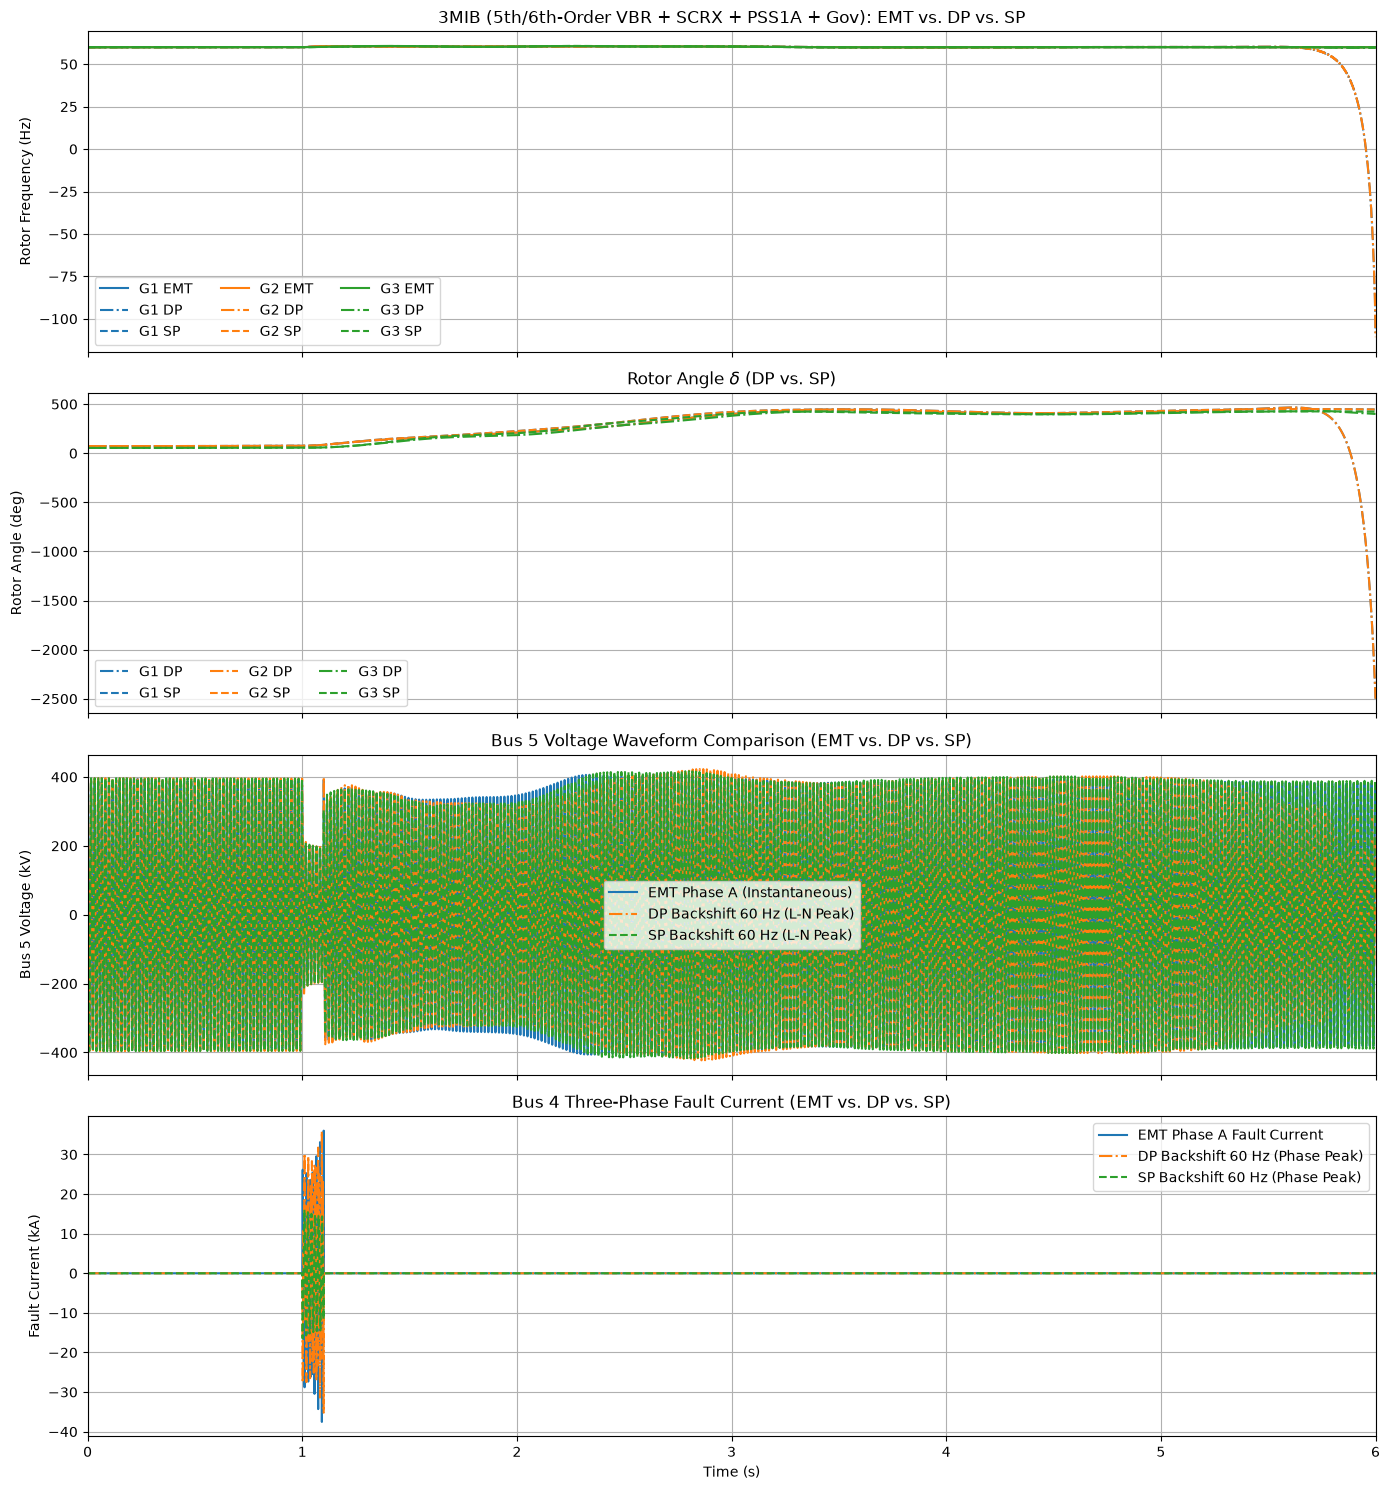

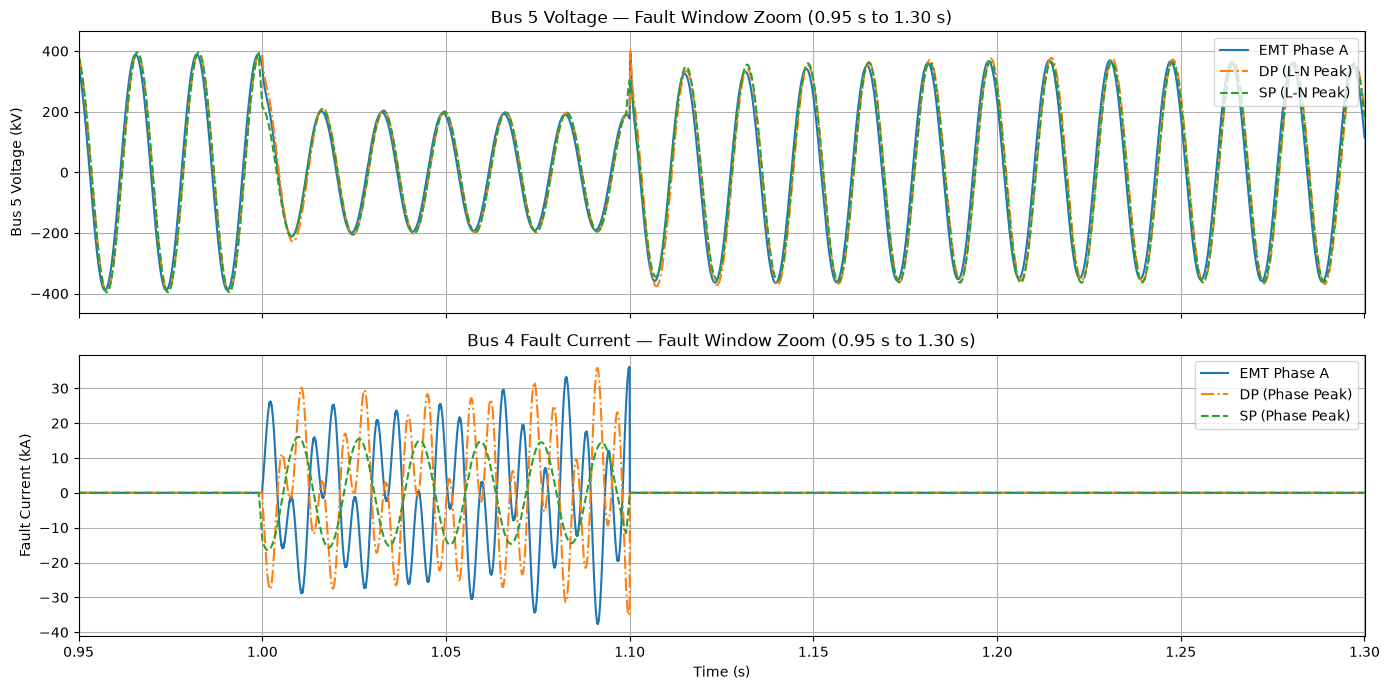

In [10]:
ts_sp  = rt.read_timeseries_dpsim("logs/3MIB_SP/3MIB_SP.csv")
ts_dp  = rt.read_timeseries_dpsim("logs/3MIB_DP/3MIB_DP.csv")
ts_emt = rt.read_timeseries_dpsim("logs/3MIB_EMT/3MIB_EMT.csv")

def report(ts_data, tag, times):
    emt = tag == "EMT"
    print(f"\n[{tag:3s}]   t   | f1[Hz]  f2[Hz]  f3[Hz] | |V1| |V4| |V5| [pu]")
    t = np.array(ts_data["wr1"].time)
    tv = np.array(ts_data["v_bus1_0" if emt else "v_bus1"].time)
    for tt in times:
        i = min(np.searchsorted(t, tt), len(t) - 1)
        j = min(np.searchsorted(tv, tt), len(tv) - 1)
        fs = [np.real(ts_data[f"wr{b}"].values[i]) * F_NOM for b in (1, 2, 3)]
        if emt:
            w = slice(max(j - 667, 0), j + 1)
            vs = [max(np.max(np.abs(np.real(ts_data[f"v_bus{b}_{ph}"].values[w]))) for ph in range(3)) / (vbase(b) * np.sqrt(2 / 3)) for b in (1, 4, 5)]
        else:
            vs = [abs(ts_data[f"v_bus{b}"].values[j]) / vbase(b) for b in (1, 4, 5)]
        print(f"        {t[i]:5.2f} | {fs[0]:7.3f} {fs[1]:7.3f} {fs[2]:7.3f} | {vs[0]:.3f} {vs[1]:.3f} {vs[2]:.3f}")

t_eval = [0, 0.99, 1.05, 1.5, 3, 5.99]
report(ts_sp,  "SP",  t_eval)
report(ts_dp,  "DP",  t_eval)
report(ts_emt, "EMT", t_eval)

# 1. Main Comparison Plots (0 to FINAL_TIME_EMT)
fig, axes = plt.subplots(4, 1, figsize=(14, 15), sharex=True)

# Rotor Frequency (Hz)
for b, color in zip((1, 2, 3), ("tab:blue", "tab:orange", "tab:green")):
    axes[0].plot(ts_emt[f"wr{b}"].time, np.real(ts_emt[f"wr{b}"].values) * F_NOM,
                 color=color, label=f"G{b} EMT")
    axes[0].plot(ts_dp[f"wr{b}"].time, np.real(ts_dp[f"wr{b}"].values) * F_NOM,
                 "-.", color=color, label=f"G{b} DP")
    axes[0].plot(ts_sp[f"wr{b}"].time, np.real(ts_sp[f"wr{b}"].values) * F_NOM,
                 "--", color=color, label=f"G{b} SP")
axes[0].set_xlim(0, FINAL_TIME_EMT)
axes[0].set_ylabel("Rotor Frequency (Hz)")
axes[0].set_title(f"3MIB ({GEN_ORDER}th/6th-Order VBR + SCRX + PSS1A + Gov): EMT vs. DP vs. SP")
axes[0].grid(True)
axes[0].legend(ncol=3)

# Rotor Angle delta (deg) — DP vs. SP (following the official DPsim example)
for b, color in zip((1, 2, 3), ("tab:blue", "tab:orange", "tab:green")):
    axes[1].plot(ts_dp[f"dl{b}"].time, np.degrees(np.real(ts_dp[f"dl{b}"].values)),
                 "-.", color=color, label=f"G{b} DP")
    axes[1].plot(ts_sp[f"dl{b}"].time, np.degrees(np.real(ts_sp[f"dl{b}"].values)),
                 "--", color=color, label=f"G{b} SP")
axes[1].set_ylabel("Rotor Angle (deg)")
axes[1].set_title("Rotor Angle $\\delta$ (DP vs. SP)")
axes[1].grid(True)
axes[1].legend(ncol=3)

# Bus 5 Voltage Waveform (kV)
scale_ph1_to_phase_peak = np.sqrt(2.0 / 3.0)
dp_v5_wave = ts_dp["v_bus5"].interpolate(DT_EMT).frequency_shift(F_NOM)
sp_v5_wave = ts_sp["v_bus5"].interpolate(DT_EMT).frequency_shift(F_NOM)

axes[2].plot(ts_emt["v_bus5_0"].time, np.real(ts_emt["v_bus5_0"].values) / 1e3,
             label="EMT Phase A (Instantaneous)")
axes[2].plot(dp_v5_wave.time, np.real(dp_v5_wave.values) * scale_ph1_to_phase_peak / 1e3,
             "-.", label="DP Backshift 60 Hz (L-N Peak)")
axes[2].plot(sp_v5_wave.time, np.real(sp_v5_wave.values) * scale_ph1_to_phase_peak / 1e3,
             "--", label="SP Backshift 60 Hz (L-N Peak)")
axes[2].set_ylabel("Bus 5 Voltage (kV)")
axes[2].set_title("Bus 5 Voltage Waveform Comparison (EMT vs. DP vs. SP)")
axes[2].grid(True)
axes[2].legend()

# Bus 4 Three-Phase Fault Current (kA)
dp_ifault_wave = ts_dp["i_fault"].interpolate(DT_EMT).frequency_shift(F_NOM)
sp_ifault_wave = ts_sp["i_fault"].interpolate(DT_EMT).frequency_shift(F_NOM)

axes[3].plot(ts_emt["i_fault"].time, np.real(ts_emt["i_fault"].values) / 1e3,
             label="EMT Phase A Fault Current")
axes[3].plot(dp_ifault_wave.time, np.real(dp_ifault_wave.values) * scale_ph1_to_phase_peak / 1e3,
             "-.", label="DP Backshift 60 Hz (Phase Peak)")
axes[3].plot(sp_ifault_wave.time, np.real(sp_ifault_wave.values) * scale_ph1_to_phase_peak / 1e3,
             "--", label="SP Backshift 60 Hz (Phase Peak)")
axes[3].set_ylabel("Fault Current (kA)")
axes[3].set_xlabel("Time (s)")
axes[3].set_title("Bus 4 Three-Phase Fault Current (EMT vs. DP vs. SP)")
axes[3].grid(True)
axes[3].legend()

fig.tight_layout()
plt.show()

# 2. Fault-Window Zoom (0.95 s to 1.30 s)
fig2, axes2 = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes2[0].plot(ts_emt["v_bus5_0"].time, np.real(ts_emt["v_bus5_0"].values) / 1e3, label="EMT Phase A")
axes2[0].plot(dp_v5_wave.time, np.real(dp_v5_wave.values) * scale_ph1_to_phase_peak / 1e3, "-.", label="DP (L-N Peak)")
axes2[0].plot(sp_v5_wave.time, np.real(sp_v5_wave.values) * scale_ph1_to_phase_peak / 1e3, "--", label="SP (L-N Peak)")
axes2[0].set_ylabel("Bus 5 Voltage (kV)")
axes2[0].set_title("Bus 5 Voltage — Fault Window Zoom (0.95 s to 1.30 s)")
axes2[0].grid(True); axes2[0].legend(loc="upper right")

axes2[1].plot(ts_emt["i_fault"].time, np.real(ts_emt["i_fault"].values) / 1e3, label="EMT Phase A")
axes2[1].plot(dp_ifault_wave.time, np.real(dp_ifault_wave.values) * scale_ph1_to_phase_peak / 1e3, "-.", label="DP (Phase Peak)")
axes2[1].plot(sp_ifault_wave.time, np.real(sp_ifault_wave.values) * scale_ph1_to_phase_peak / 1e3, "--", label="SP (Phase Peak)")
axes2[1].set_ylabel("Fault Current (kA)")
axes2[1].set_xlabel("Time (s)")
axes2[1].set_title("Bus 4 Fault Current — Fault Window Zoom (0.95 s to 1.30 s)")
axes2[1].grid(True); axes2[1].legend(loc="upper right")
axes2[1].set_xlim(0.95, 1.30)

fig2.tight_layout()
plt.show()